Importing Data + installing requried packages

In [1]:
from pathlib import Path
import pandas as pd

def find_project_root(marker=".git", start=None):
    """Walk up from the current directory until we find the repo root
    (identified by the presence of a .git folder)."""
    current = Path(start or Path.cwd()).resolve()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate project root (no {marker} found above {current})."
    )

PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data" / "raw"
SUBMISSION_DIR = PROJECT_DIR / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

def resolve_data_file(canonical_name, fallback_name):
    """Prefer data/raw; retain compatibility with the current root-level download."""
    canonical_path = DATA_DIR / canonical_name
    fallback_path = DATA_DIR / fallback_name  # fixed: was PROJECT_DIR
    if canonical_path.exists():
        return canonical_path
    if fallback_path.exists():
        print(f"Using fallback file: {fallback_path.name}")
        return fallback_path
    raise FileNotFoundError(
        f"Could not find {canonical_path} or {fallback_path}. "
        "Place the competition CSVs in data/raw."
    )

TRAIN_PATH = resolve_data_file("train.csv", "train (1).csv")
TEST_PATH = resolve_data_file("test.csv", "test (1).csv")
SAMPLE_SUBMISSION_PATH = resolve_data_file(
    "sample_submission.csv", "sample_submission.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)

test_passenger_ids = test_df["PassengerId"].copy()
train_df["is_train"] = True
test_df["is_train"] = False
combined_raw = pd.concat([train_df, test_df], ignore_index=True, sort=False)

print(f"Project root: {PROJECT_DIR}")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Combined shape: {combined_raw.shape}")
display(sample_submission.head())

Using fallback file: train (1).csv
Using fallback file: test (1).csv
Project root: /workspaces/alpha-centauri-rescue
Train shape: (8693, 15)
Test shape: (4277, 14)
Combined shape: (12970, 15)


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [2]:
from pathlib import Path
from collections import Counter
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost",
}

for package, import_name in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")


In [5]:
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,is_train
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,True
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,True
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,True
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,True
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,True
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,True


In [7]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train'],
      dtype='str')

In [21]:
train_df['is_train'][:100]

0     True
1     True
2     True
3     True
4     True
      ... 
95    True
96    True
97    True
98    True
99    True
Name: is_train, Length: 100, dtype: bool

FILL NULL AND MISSING VALUES 

In [22]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train'],
      dtype='str')

In [25]:
train_df['HomePlanet'].describe()


count      8492
unique        3
top       Earth
freq       4602
Name: HomePlanet, dtype: object

In [26]:
train_df['HomePlanet'].value_counts()

HomePlanet
Earth     4602
Europa    2131
Mars      1759
Name: count, dtype: int64

In [27]:
train_df['HomePlanet'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: HomePlanet
Non-Null Count  Dtype
--------------  -----
8492 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [28]:
train_df['HomePlanet'].isna().sum()

np.int64(201)

Note: you may need to restart the kernel to use updated packages.


<Axes: >

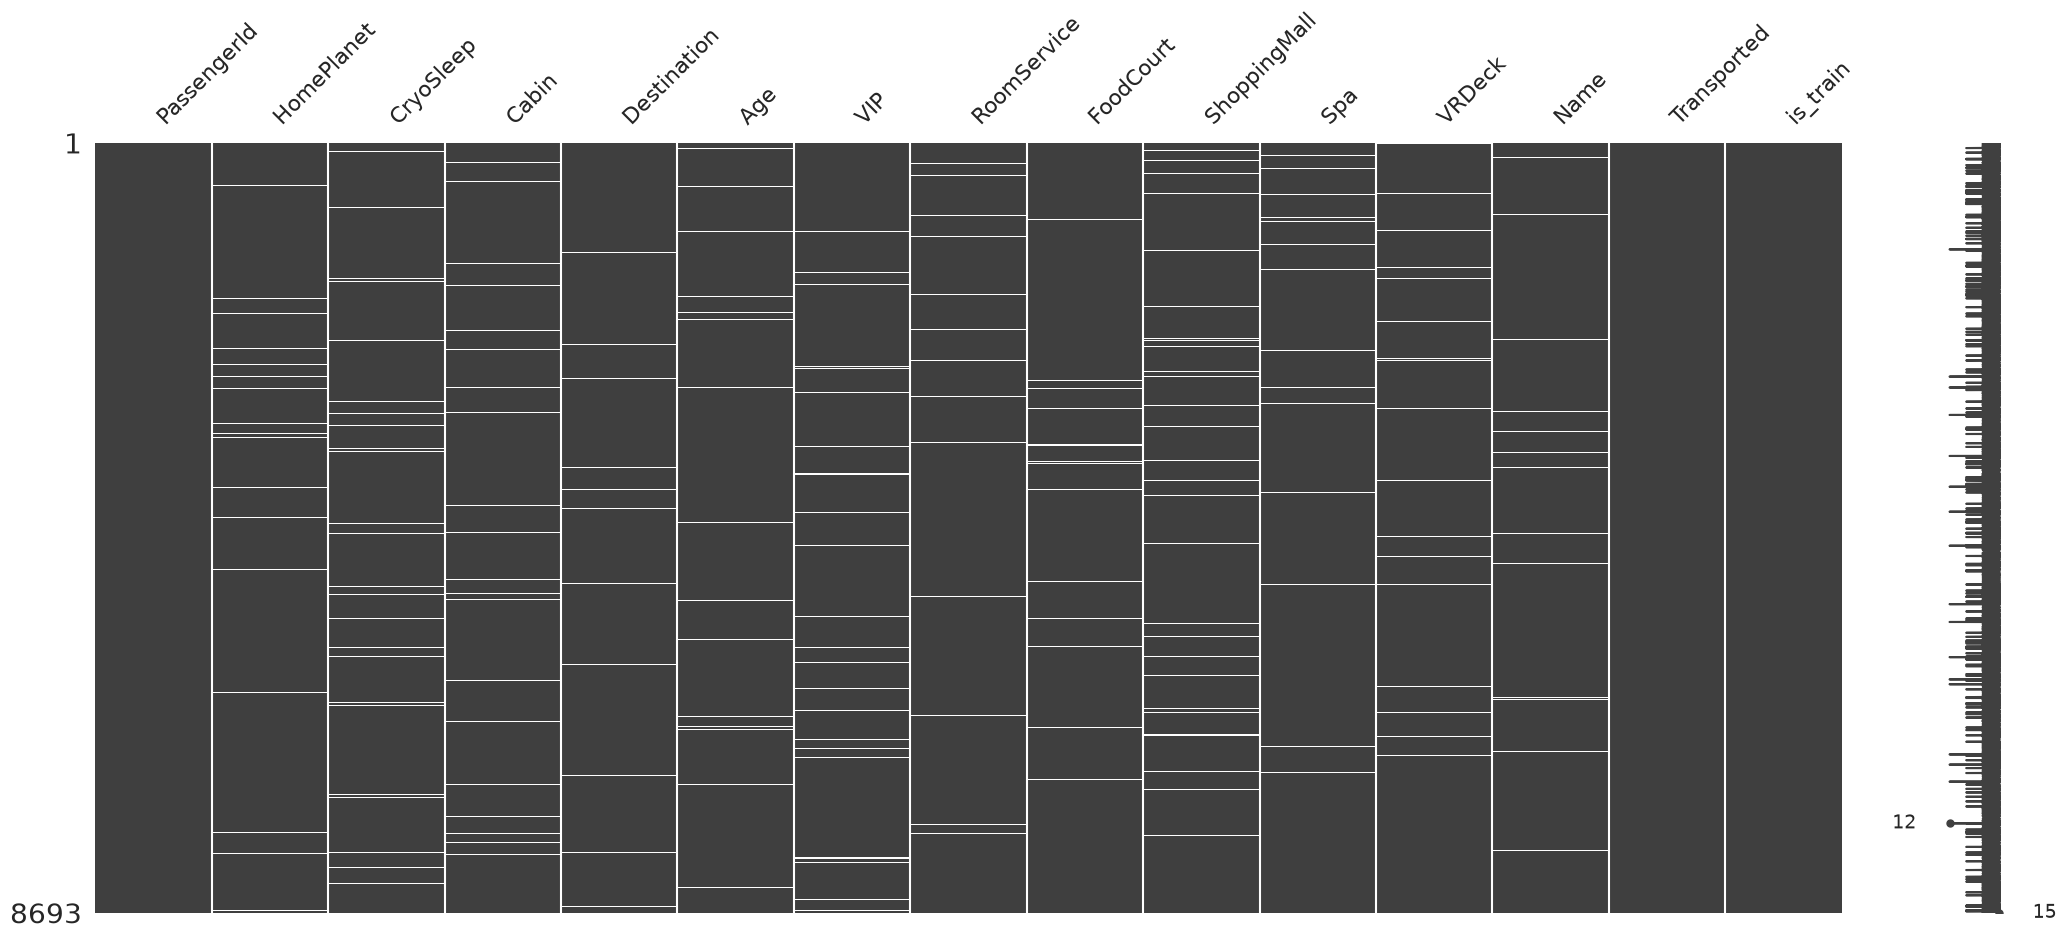

In [32]:
%pip install missingno
train_df['HomePlanet'].isna().mean() * 100
import missingno as msno
msno.matrix(train_df)

<Axes: >

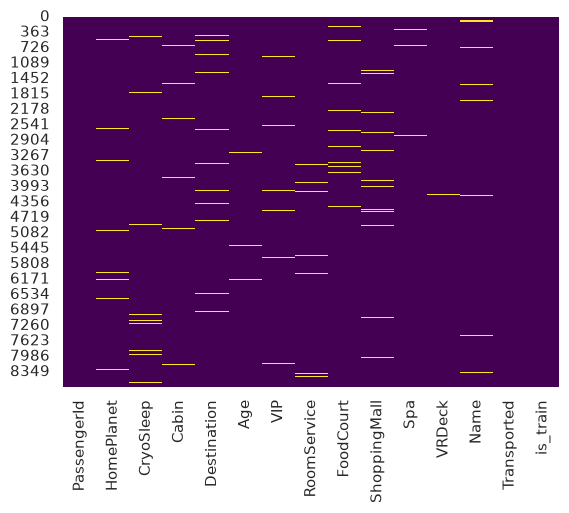

In [33]:
sns.heatmap(train_df.isna(), cbar=False, cmap='viridis')

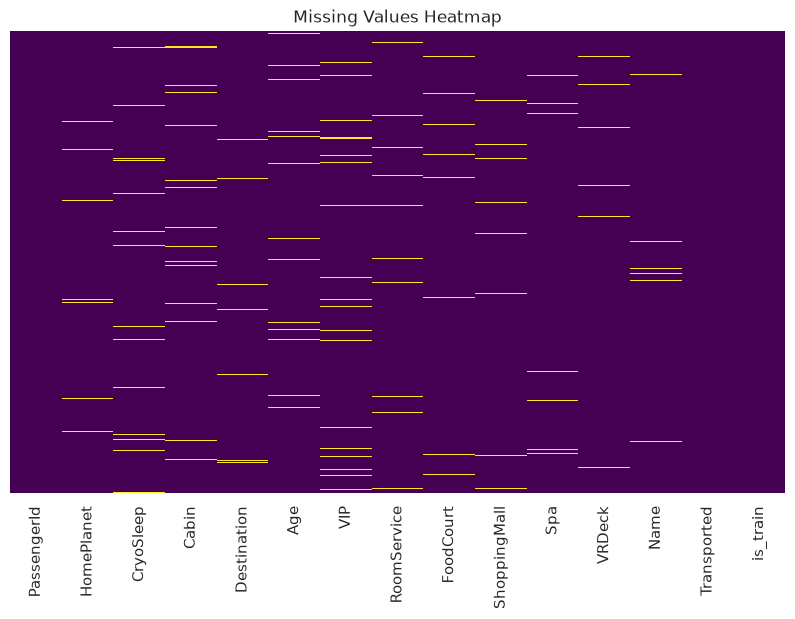

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(train_df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()

In [37]:
train_df['HomePlanet'] = train_df['HomePlanet'].fillna('Earth')

In [39]:
train_df['HomePlanet'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: HomePlanet
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [40]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train'],
      dtype='str')

In [41]:
train_df['CryoSleep'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: CryoSleep
Non-Null Count  Dtype 
--------------  ----- 
8476 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [42]:
train_df['CryoSleep'].describe()
train_df['CryoSleep'].value_counts()

CryoSleep
False    5439
True     3037
Name: count, dtype: int64

In [43]:
train_df['CryoSleep'] = train_df['CryoSleep'].fillna(False)

In [44]:
train_df['CryoSleep'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: CryoSleep
Non-Null Count  Dtype 
--------------  ----- 
8693 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [45]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train'],
      dtype='str')

In [46]:
train_df['Cabin'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [48]:
train_df['Cabin'].value_counts()
train_df['Cabin'].describe()

count        8494
unique       6560
top       G/734/S
freq            8
Name: Cabin, dtype: object

Split Cabin from combined Deck/Cabin Number/Side into -cabin_deck,cabin_num and Cabin_side

In [49]:
# Extract Group ID from PassengerId
train_df['Group'] = train_df['PassengerId'].apply(lambda x: x.split('_')[0])

# Split Cabin into three separate features
train_df[['Cabin_deck', 'Cabin_num', 'Cabin_side']] = train_df['Cabin'].str.split('/', expand=True)
train_df['Cabin_num'] = train_df['Cabin_num'].astype(float)

In [51]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [52]:
train_df['Cabin_side'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_side
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [53]:
train_df['Cabin_side'].describe()
train_df['Cabin_side'].value_counts()

Cabin_side
S    4288
P    4206
Name: count, dtype: int64

In [54]:
train_df['Cabin_side'] = train_df['Cabin_side'].fillna('S')  # Assuming 'S' is the most common side

In [56]:
train_df['Cabin_side'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_side
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [57]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [58]:
train_df['Cabin_num'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_num
Non-Null Count  Dtype  
--------------  -----  
8494 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [59]:
train_df['Cabin_num'].describe()
train_df['Cabin_num'].value_counts()

Cabin_num
82.0      28
19.0      22
86.0      22
56.0      21
97.0      21
          ..
1886.0     1
1891.0     1
1892.0     1
1893.0     1
1894.0     1
Name: count, Length: 1817, dtype: int64

In [63]:
train_df['Cabin_num'] = train_df['Cabin_num'].fillna(82.0)

In [64]:
train_df['Cabin_num'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_num
Non-Null Count  Dtype  
--------------  -----  
8693 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [65]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [66]:
train_df['Cabin_deck'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_deck
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [67]:
train_df['Cabin_deck'].describe()
train_df['Cabin_deck'].value_counts()

Cabin_deck
F    2794
G    2559
E     876
B     779
C     747
D     478
A     256
T       5
Name: count, dtype: int64

In [68]:
train_df['Cabin_deck'] = train_df['Cabin_deck'].fillna('F')

In [69]:
train_df['Cabin_deck'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_deck
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [70]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [71]:
train_df = train_df.drop(columns=['Cabin'])

In [72]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name',
       'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [73]:
train_df['Destination'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Destination
Non-Null Count  Dtype
--------------  -----
8511 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [74]:
train_df['Destination'].describe()
train_df['Destination'].value_counts()

Destination
TRAPPIST-1e      5915
55 Cancri e      1800
PSO J318.5-22     796
Name: count, dtype: int64

In [75]:
train_df['Destination'] = train_df['Destination'].fillna('TRAPPIST-1e')

In [76]:
train_df['Destination'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Destination
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [77]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name',
       'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [79]:
train_df['Age'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
8514 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [80]:
train_df['Age'].describe()
train_df['Age'].value_counts()

Age
24.0    324
18.0    320
21.0    311
19.0    293
23.0    292
       ... 
72.0      4
79.0      3
78.0      3
76.0      2
77.0      2
Name: count, Length: 80, dtype: int64

In [81]:
train_df['Age'] = train_df['Age'].fillna(24.0)

In [82]:
train_df['Age'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
8693 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [83]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name',
       'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [84]:
train_df['VIP'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: VIP
Non-Null Count  Dtype 
--------------  ----- 
8490 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [85]:
train_df['VIP'].describe()
train_df['VIP'].value_counts()

VIP
False    8291
True      199
Name: count, dtype: int64

In [86]:
train_df['VIP'] = train_df['VIP'].fillna(False)

In [87]:
train_df['VIP'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: VIP
Non-Null Count  Dtype 
--------------  ----- 
8693 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [88]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name',
       'Transported', 'is_train', 'Group', 'Cabin_deck', 'Cabin_num',
       'Cabin_side'],
      dtype='str')

In [89]:
train_df['Name'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Name
Non-Null Count  Dtype
--------------  -----
8493 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [90]:
train_df['Name'].describe()
train_df['Name'].value_counts()

Name
Elaney Webstephrey    2
Keitha Josey          2
Ankalik Nateansive    2
Gollux Reedall        2
Grake Porki           2
                     ..
Gravior Noxnuther     1
Kurta Mondalley       1
Fayey Connon          1
Celeon Hontichre      1
Propsh Hontichre      1
Name: count, Length: 8473, dtype: int64